In [1]:
import numpy as np 
import pandas as pd 
from matplotlib import pyplot as plt 
from scipy import stats
from sklearn.metrics. pairwise import cosine_similarity

# AdsFlow: Diagnostic Analysis of Flow Matching for Adsorbate Structure Relaxation

## Summary

This report presents a comprehensive diagnostic analysis of AdsFlow, a flow matching model for predicting relaxed adsorbate-catalyst structures. The key findings are:

1. **Baseline Performance**: State-of-the-art MLFF methods (EquiformerV2) achieve excellent overall structural relaxation (MAE = 0.05 Å) but struggle with adsorbate placement (MAE = 0.15 Å), motivating the need for generative approaches.

2. **Model Selection**: EquiformerV2 outperforms GemNet-OC despite having fewer parameters (53M vs 89M), with GemNet-OC showing overfitting tendencies.

3. **AdsFlow Performance**: On the OC20 Val-OOD-Both dataset, AdsFlow reduces initial structure MAE by 0.08 Å to a final MAE of 0.12 Å. Adsorbate atoms show higher error, which correlates with their larger required displacements during relaxation.

4. **Velocity Field Analysis**: The model correctly predicts the direction of atomic displacement vectors (high cosine similarity) but systematically underestimates the magnitude, particularly for adsorbate atoms -> this was unclear from structural MAE analyses. This represents the primary avenue for model improvement.

# MLFF Benchmark - EquiformerV2

We begin this analysis by examining the performance of state-of-the-art machine learning force field (MLFF) methods for structural relaxations. This establishes a baseline for comparison with our generative approach.

In [2]:
# Load test set metrics
mlff_mae = np.load('mlff_val_data/generated_mae.npy')
mlff_ads_mae = np.load('mlff_val_data/generated_ads_mae.npy')

**Observations:**
- The MLFF achieves excellent overall relaxation performance with an MAE of 0.05 Å.
- However, adsorbate placement remains challenging, with an adsorbate-specific MAE of 0.15 Å (3× higher than overall).
- This performance gap motivates our generative modeling approach: AdsFlow specifically targets the adsorbate placement challenge. When combined with MLFF, it should improve adsorbate positioning accuracy.

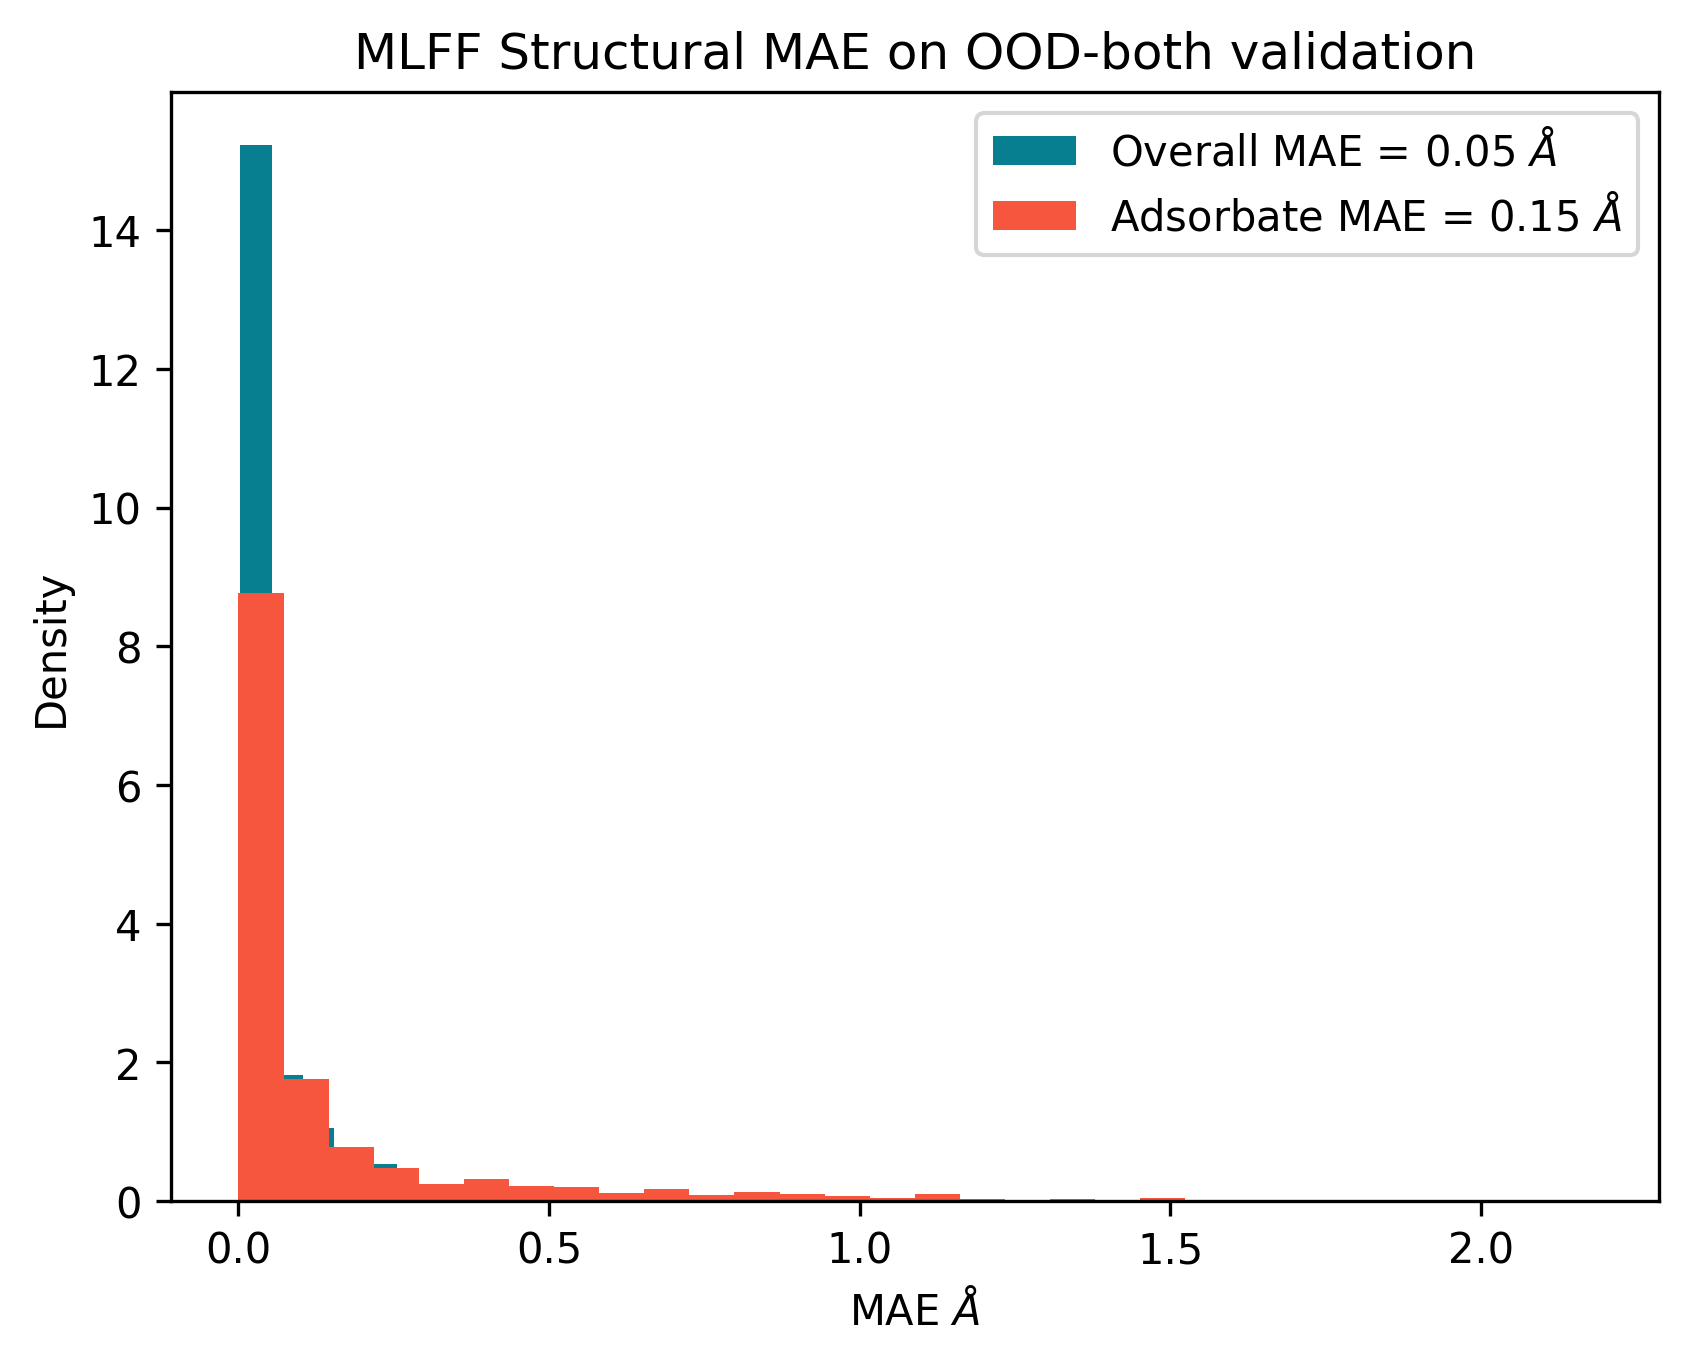

In [3]:
plt.figure(dpi=300)
plt.hist(mlff_mae, bins=30,  density=True, label=f'Overall MAE = {mlff_mae.mean():.2f} $\AA$', color="#087F91")
plt.hist(mlff_ads_mae, bins=30,  density=True, label=f'Adsorbate MAE = {mlff_ads_mae.mean():.2f} $\AA$', color="#F5563D")
plt.xlabel("MAE $\AA$")
plt.ylabel("Density")
plt.title("MLFF Structural MAE on OOD-both validation")
plt.legend()

# Model training

We trained two flow matching models using different neural network architectures: GemNet-OC and EquiformerV2. Both architectures respect system symmetries, periodic boundary conditions (PBC), and E(3) invariances/equivariances.

In [4]:
# Read the loss data
df = pd.read_csv('loss_curves/gemnet_equv2_loss.csv')

**Observations:**
- EquiformerV2 outperforms GemNet-OC despite having fewer parameters (53M vs 89M).
- GemNet-OC exhibits overfitting behavior, as evidenced by the divergence between training and validation loss.
- Based on these results, all subsequent analysis focuses exclusively on the EquiformerV2-based model.

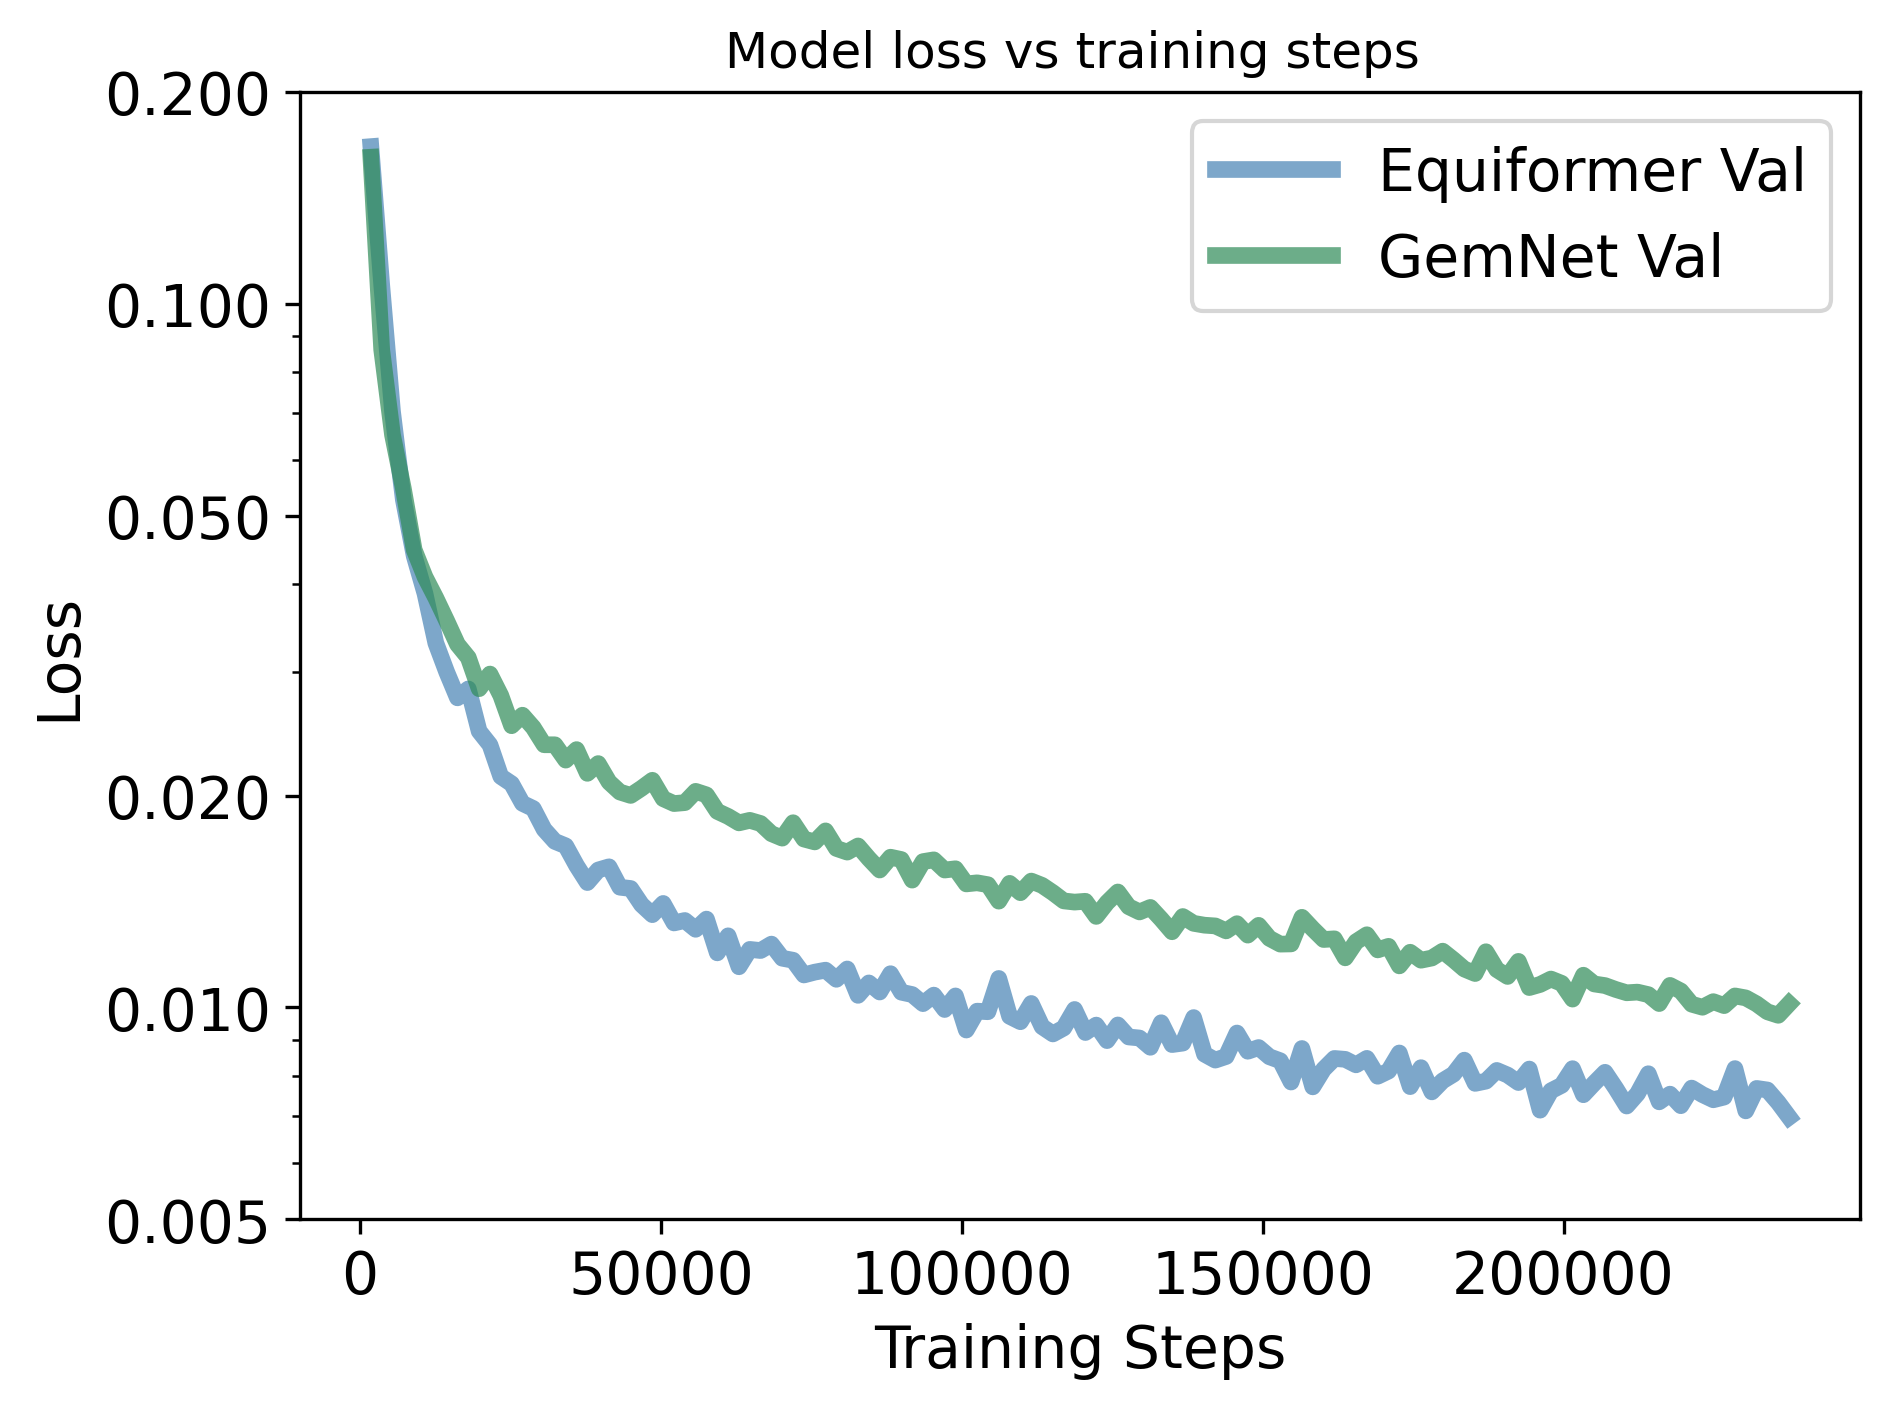

In [5]:
# Extract columns
steps = df['trainer/global_step']
equiformer_train_loss = df['equiformer-base - train/loss_epoch']
equiformer_val_loss = df['equiformer-base - val/loss']
gemnet_train_loss = df['gemnet-oc - train/loss_epoch']
gemnet_val_loss = df['gemnet-oc - val/loss']

# Find last valid index for equiformer data
last_valid_idx = equiformer_train_loss.last_valid_index()

# Plot training and validation loss curves
plt.figure(dpi=300)

# Validation losses (dashed lines)
plt.plot(steps[:last_valid_idx+1], equiformer_val_loss[:last_valid_idx+1], label='Equiformer Val', color='steelblue', linewidth=4, alpha=0.7)
plt.plot(steps[:last_valid_idx+1], gemnet_val_loss[:last_valid_idx+1], label='GemNet Val', color='seagreen', linewidth=4, alpha=0.7)

plt.yscale('log')
plt.yticks([0.005, 0.01, 0.02, 0.05, 0.1, 0.2])
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x:.3f}'))
plt.xlabel('Training Steps', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.legend(fontsize=14)
plt.tick_params(axis='both', labelsize=14)
plt.title("Model loss vs training steps ")
plt.tight_layout()

# OOD-Both Validation performance 

We evaluate AdsFlow performance using the OC20 validation dataset, specifically the Val-OOD-Both split, which contains out-of-distribution samples for both adsorbate and catalyst compositions.

In [6]:
# Load test set metrics
initial_mae = np.load('val_ood_both_base-metrics/initial_mae.npy')
generated_mae = np.load('val_ood_both_base-metrics/generated_mae.npy')

# Load test set metrics
initial_ads_mae = np.load('val_ood_both_base-metrics/initial_ads_mae.npy')
generated_ads_mae = np.load('val_ood_both_base-metrics/generated_ads_mae.npy')

initial_cat_mae = np.load('test_metrics/initial_mae.npy')
generated_cat_mae = np.load('test_metrics/generated_mae.npy')

# Load test set metrics
generated_me = np.load('val_ood_both_base-metrics/generated_me.npy')
generated_ads_me = np.load('val_ood_both_base-metrics/generated_ads_me.npy')

initial_me = np.load('val_ood_both_base-metrics/initial_me.npy')
initial_ads_me = np.load('val_ood_both_base-metrics/initial_ads_me.npy')

initial_cat_me = np.load('test_metrics/initial_me.npy')
generated_cat_me = np.load('test_metrics/generated_me.npy')




**Observations:**
- AdsFlow reduces the MAE of initial structures by 0.08 Å, achieving a total MAE of 0.12 Å across all structures.
- Adsorbate atoms exhibit higher MAE than the overall average, which is expected given that adsorbates undergo the largest displacements during relaxation (as indicated by the initial MAE distribution).
- The central diagnostic question is whether the elevated adsorbate error reflects (1) a limitation in the model's ability to learn adsorbate velocity fields, or (2) an inherent dataset imbalance where adsorbates are underrepresented.

Text(0.5, 1.0, 'Initial vs generated per adsorbate MAE')

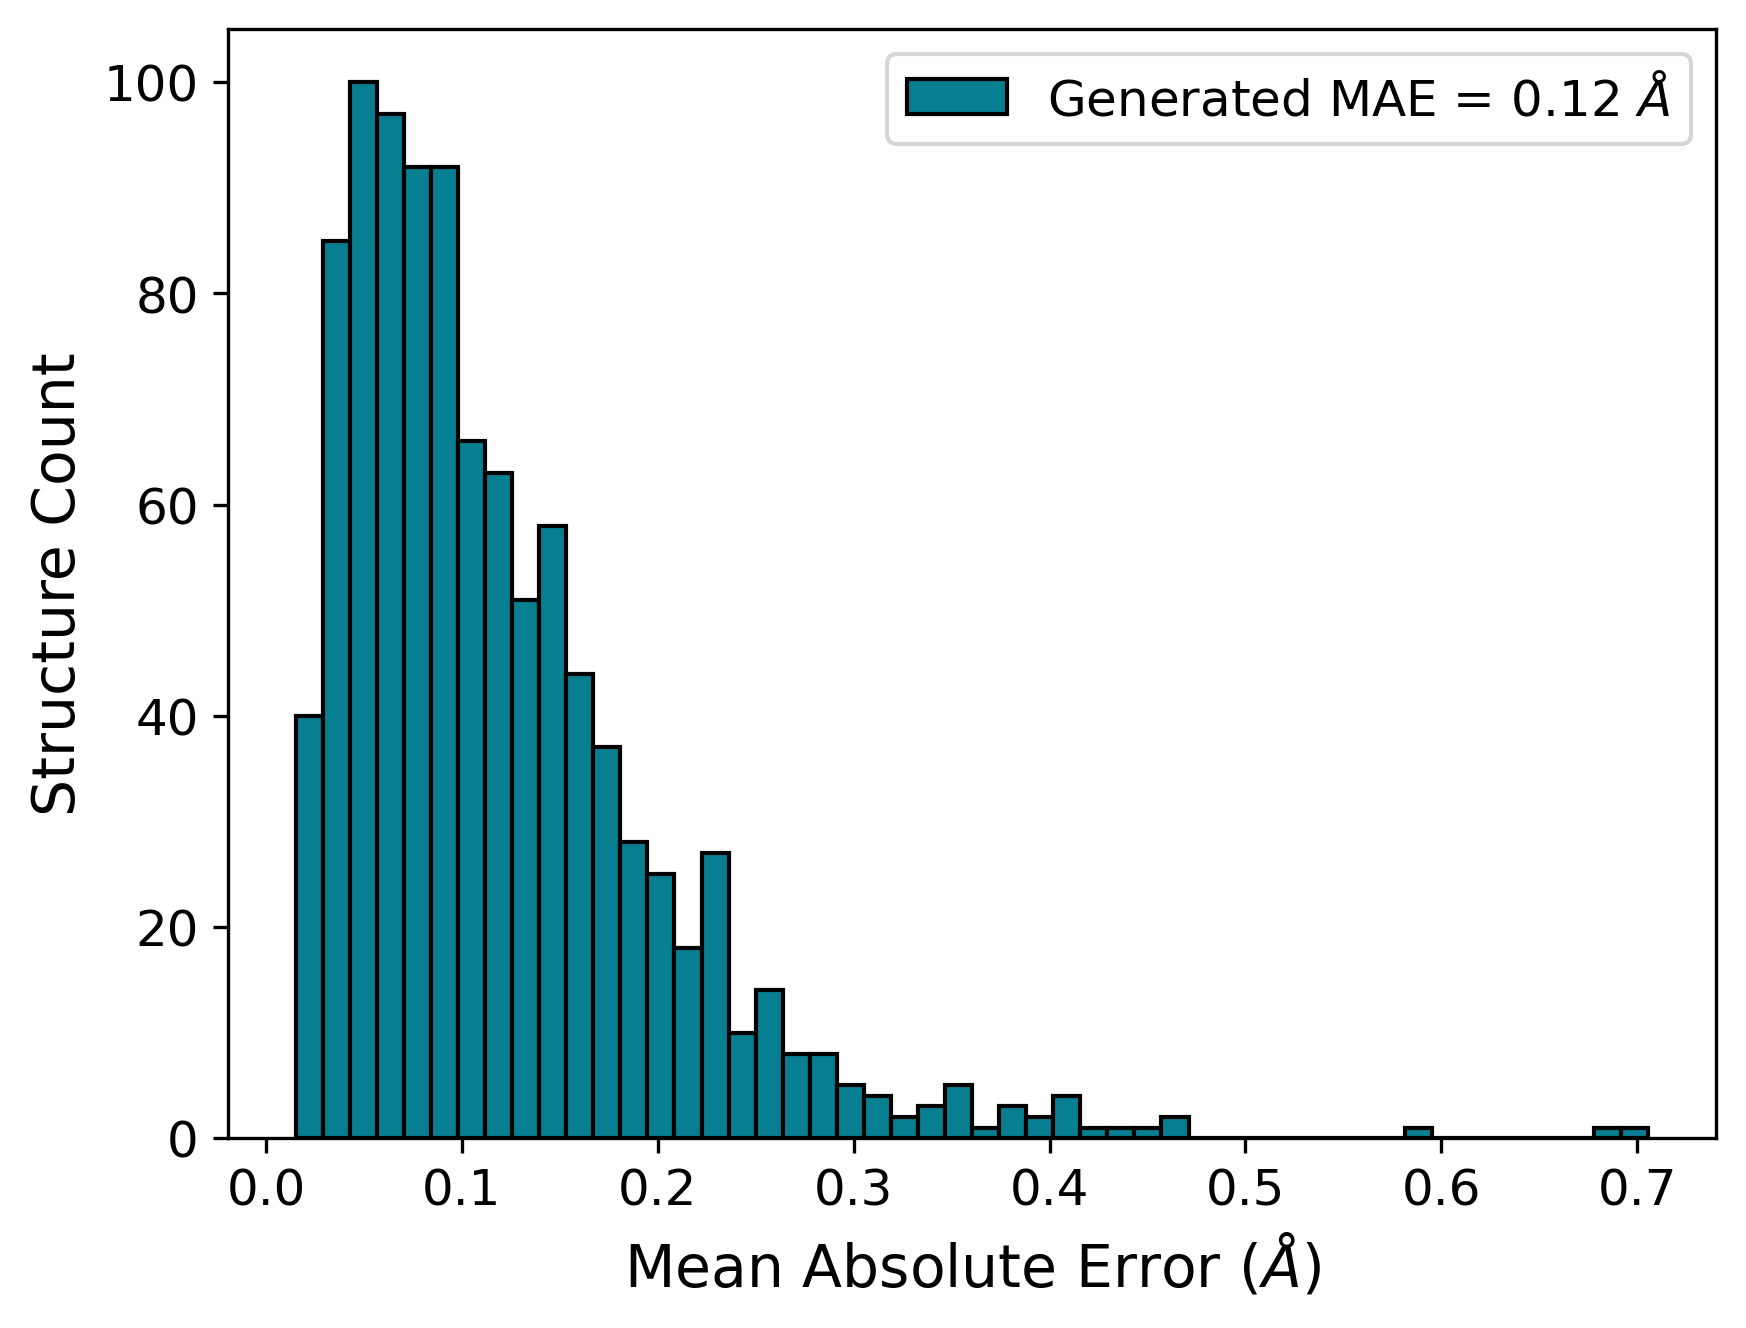

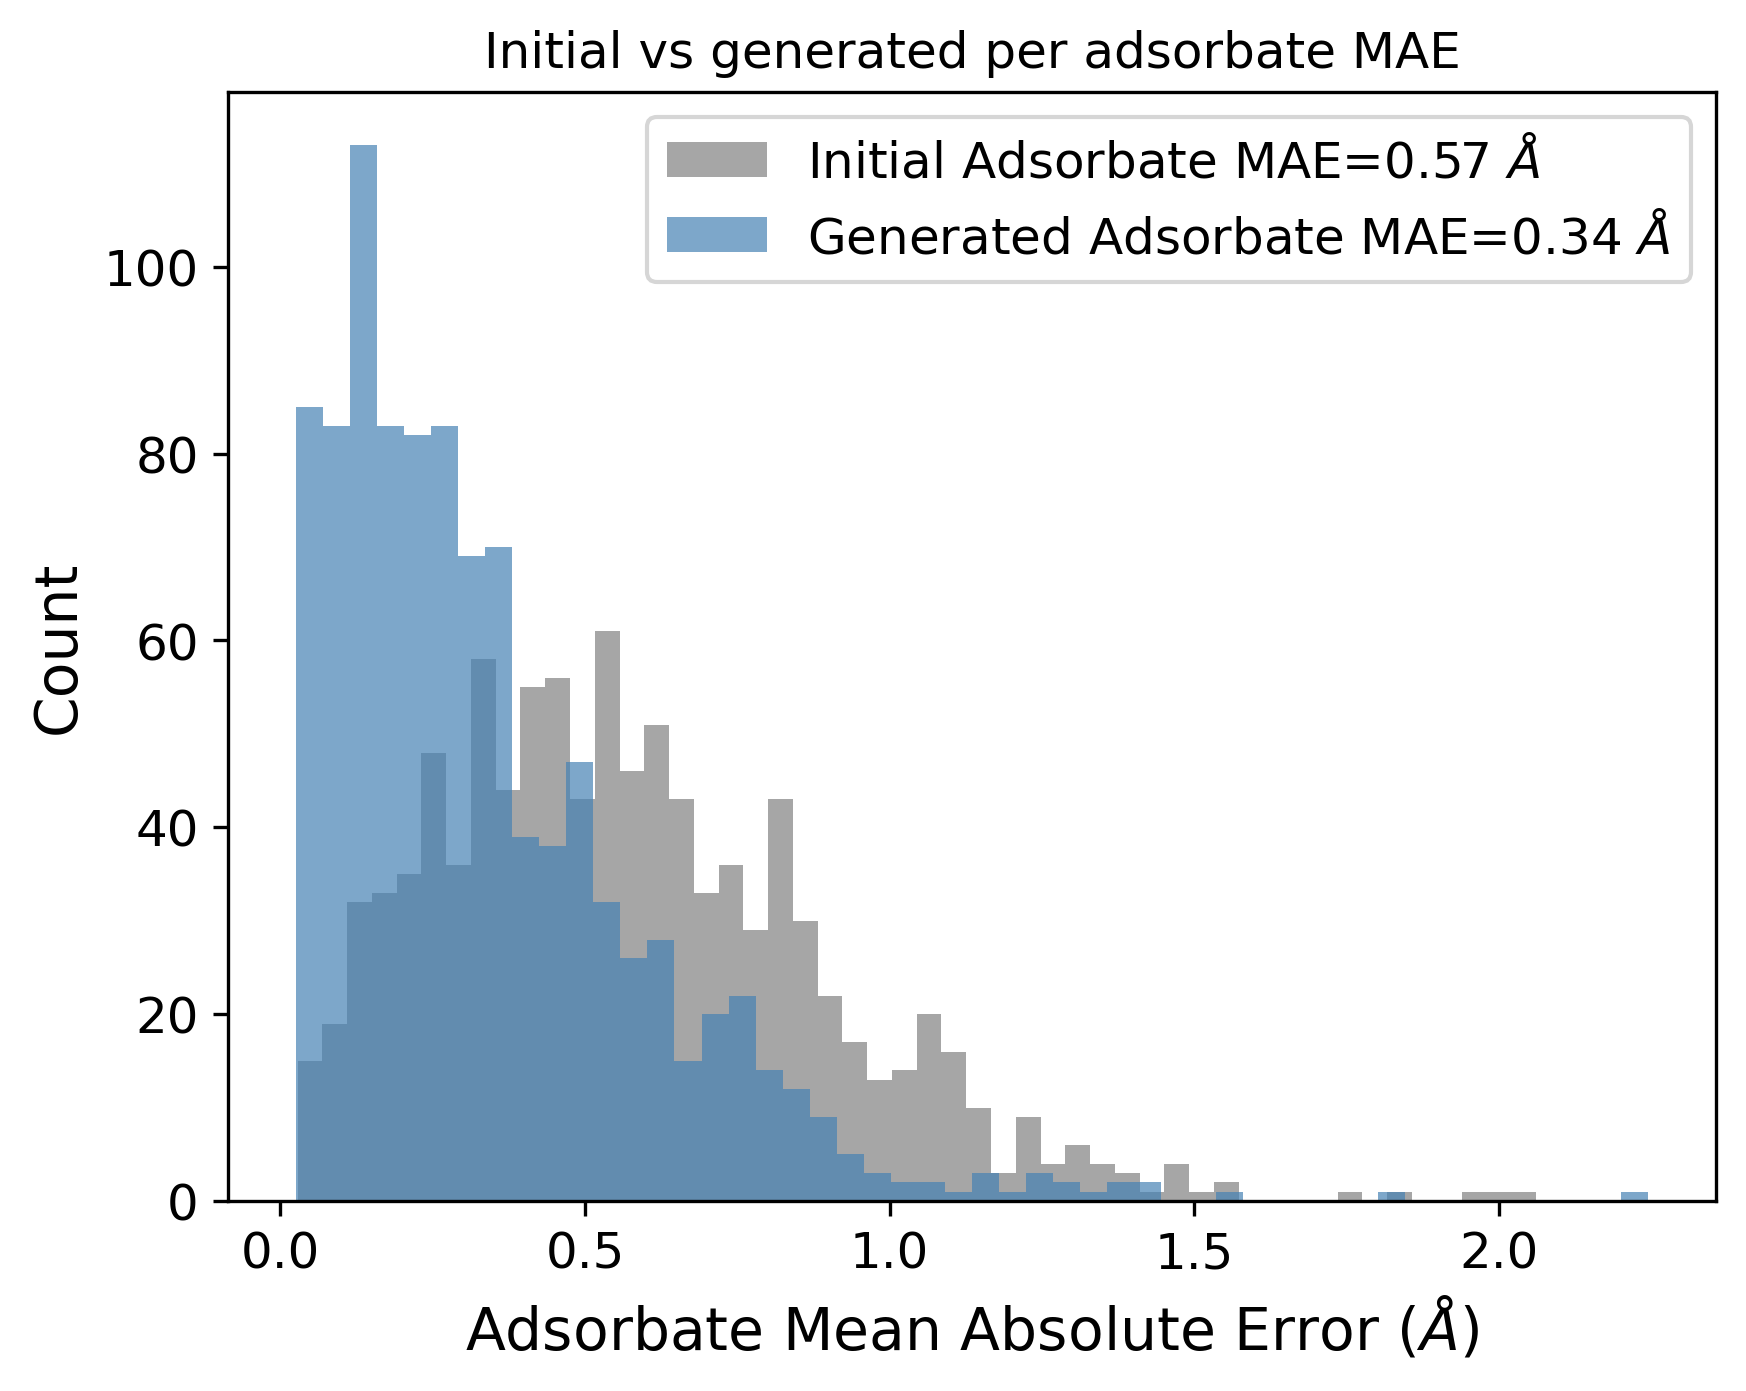

In [22]:
# Create histogram for MAE
plt.figure(dpi=300)

#plt.hist(initial_mae, bins=50, alpha=0.7, label=f'Initial MAE = {initial_mae.mean():.2f} $\AA$', color='grey')
plt.hist(generated_mae, bins=50, label=f'Generated MAE = {generated_mae.mean():.2f} $\AA$', color="#087F91", edgecolor='black')
plt.xlabel('Mean Absolute Error ($\AA$)', fontsize=14)
plt.ylabel('Structure Count', fontsize=14)
plt.legend(fontsize=12)
plt.tick_params(axis='both', labelsize=12)
#plt.title("Initial vs generated per structure MAE")
plt.savefig("generated_mae.pdf", dpi=300, bbox_inches='tight')

# Create histogram for MAE
plt.figure(dpi=300)

plt.hist(initial_ads_mae, bins=50, alpha=0.7, label=f'Initial Adsorbate MAE={initial_ads_mae.mean():.2f} $\AA$', color='grey')
plt.hist(generated_ads_mae, bins=50, alpha=0.7, label=f'Generated Adsorbate MAE={generated_ads_mae.mean():.2f} $\AA$', color='steelblue')
plt.xlabel('Adsorbate Mean Absolute Error ($\AA$)', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(fontsize=12)
plt.tick_params(axis='both', labelsize=12)
plt.title("Initial vs generated per adsorbate MAE")

### Correlation Analysis: Displacement vs. Error

To diagnose model performance on adsorbates, we examine two key correlations:

**Plot 1 - Generated MAE vs Initial MAE:** This reveals whether the model struggles with adsorbates requiring large displacements. A positive correlation indicates that atoms needing to move further tend to have higher final errors.

**Plot 2 - Relative MAE vs Initial MAE:** By plotting (Generated MAE / Initial MAE) against Initial MAE, we assess whether the model actively improves difficult cases. Key observations:
- Values < 1 indicate improvement over the initial structure
- Values > 1 indicate the model made the structure worse
- A negative slope suggests the model provides greater relative improvement for atoms with larger required displacements

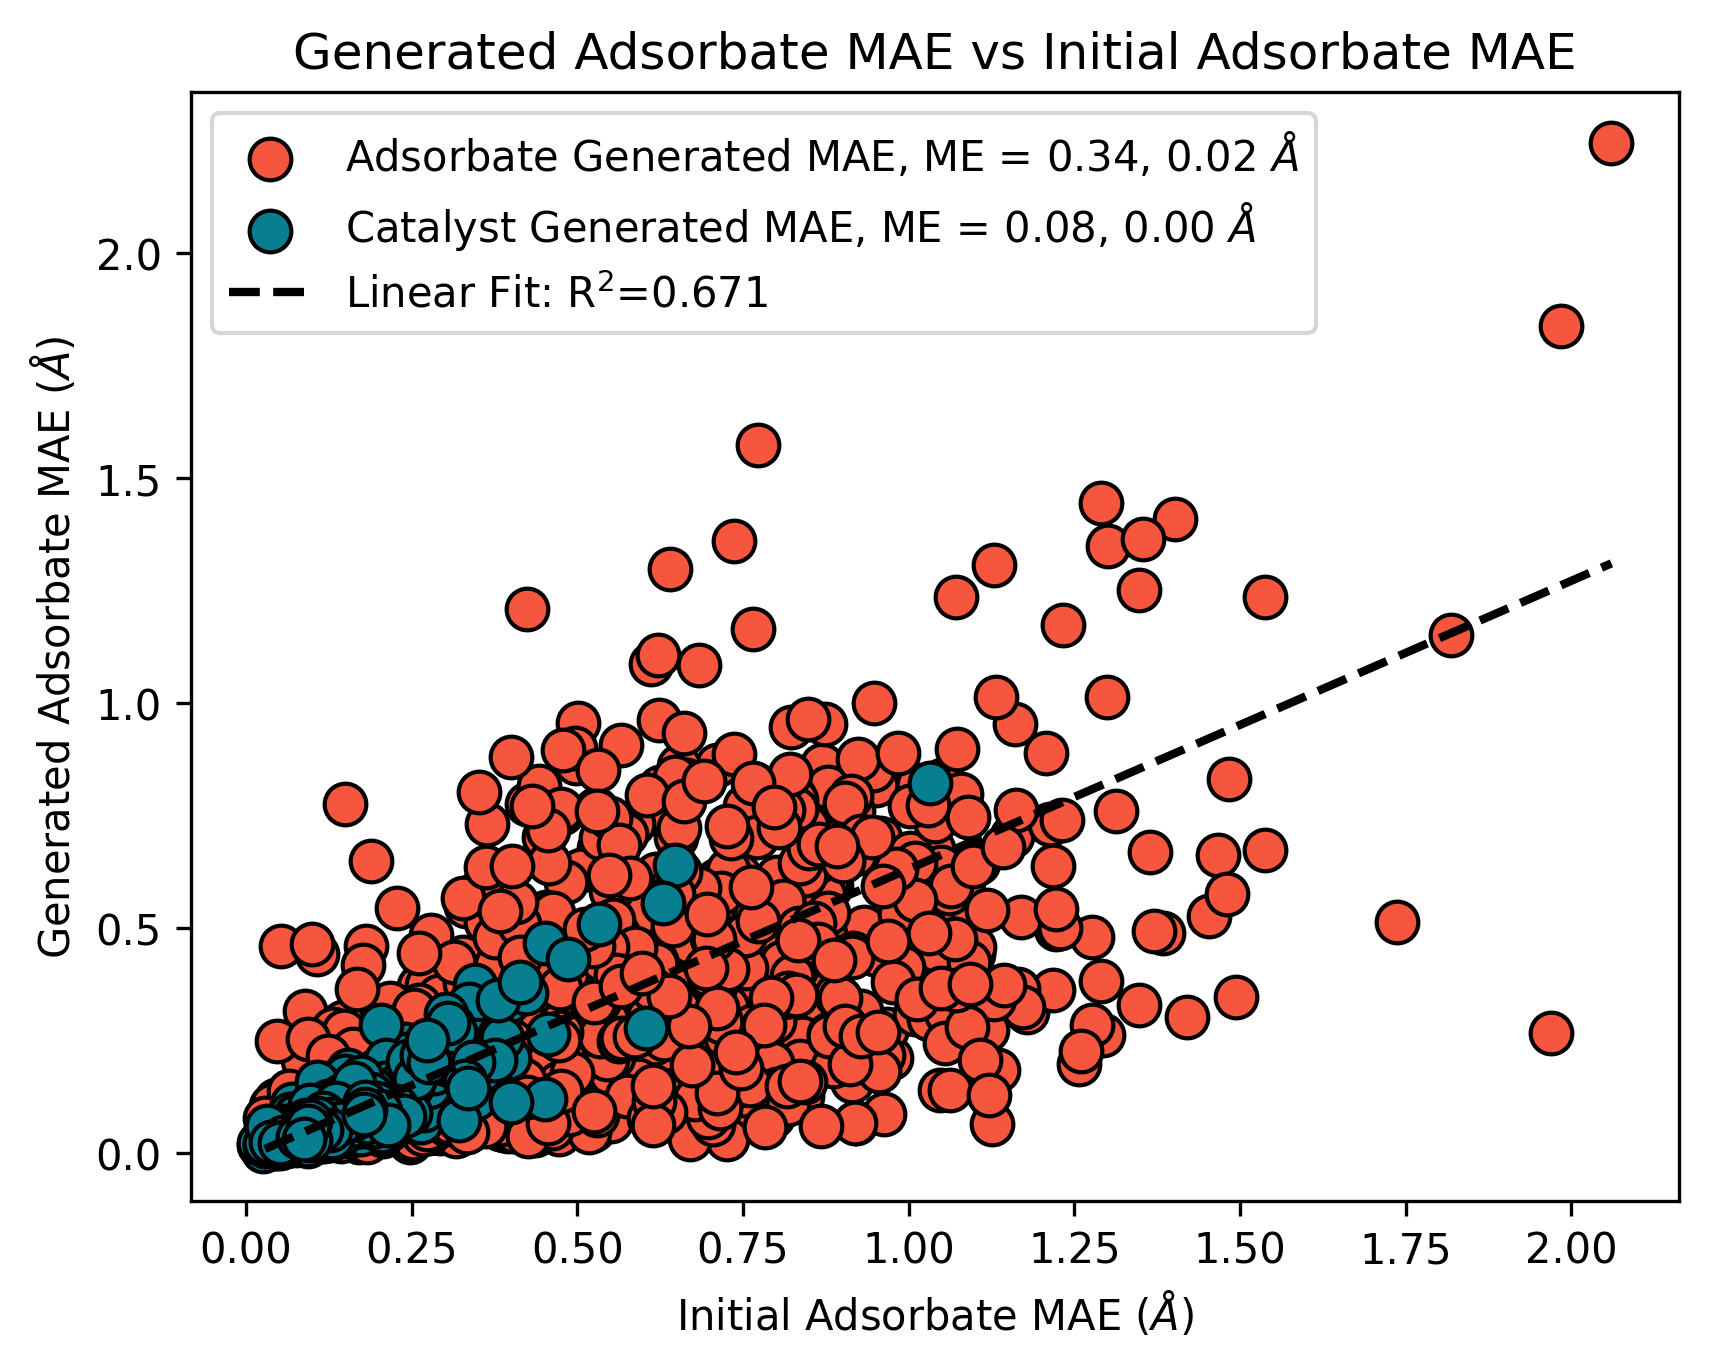

In [8]:
slope, intercept, r_value, p_value, std_err = stats.linregress(initial_mae, generated_mae)
r_squared = r_value**2

# Generate regression line
x_reg = np.linspace(initial_ads_mae.min(), initial_ads_mae.max(), 100)
y_reg = slope * x_reg + intercept

plt.figure(dpi=300)
plt.scatter(
    initial_ads_mae,
    generated_ads_mae,
    s=100,      # or e.g. 5 + 3*counts to exaggerate
    edgecolors="black", 
    color="#F5563D",
    label=f'Adsorbate Generated MAE, ME = {generated_ads_mae.mean():.2f}, {generated_ads_me.mean():.2f} $\AA$'
)

plt.scatter(
    initial_cat_mae,
    generated_cat_mae,
    s=100,      # or e.g. 5 + 3*counts to exaggerate
    edgecolors="black", 
    color="#087F91",
    label=f'Catalyst Generated MAE, ME = {generated_cat_mae.mean():.2f}, {generated_cat_me.mean():.2f} $\AA$',
)
plt.plot(x_reg, y_reg, color="black", linewidth=2, linestyle="--", label=f"Linear Fit: R$^2$={r_squared:.3f}")
plt.ylabel("Generated Adsorbate MAE ($\AA$)")
plt.xlabel("Initial Adsorbate MAE ($\AA$)")
plt.title("Generated Adsorbate MAE vs Initial Adsorbate MAE")
plt.legend()

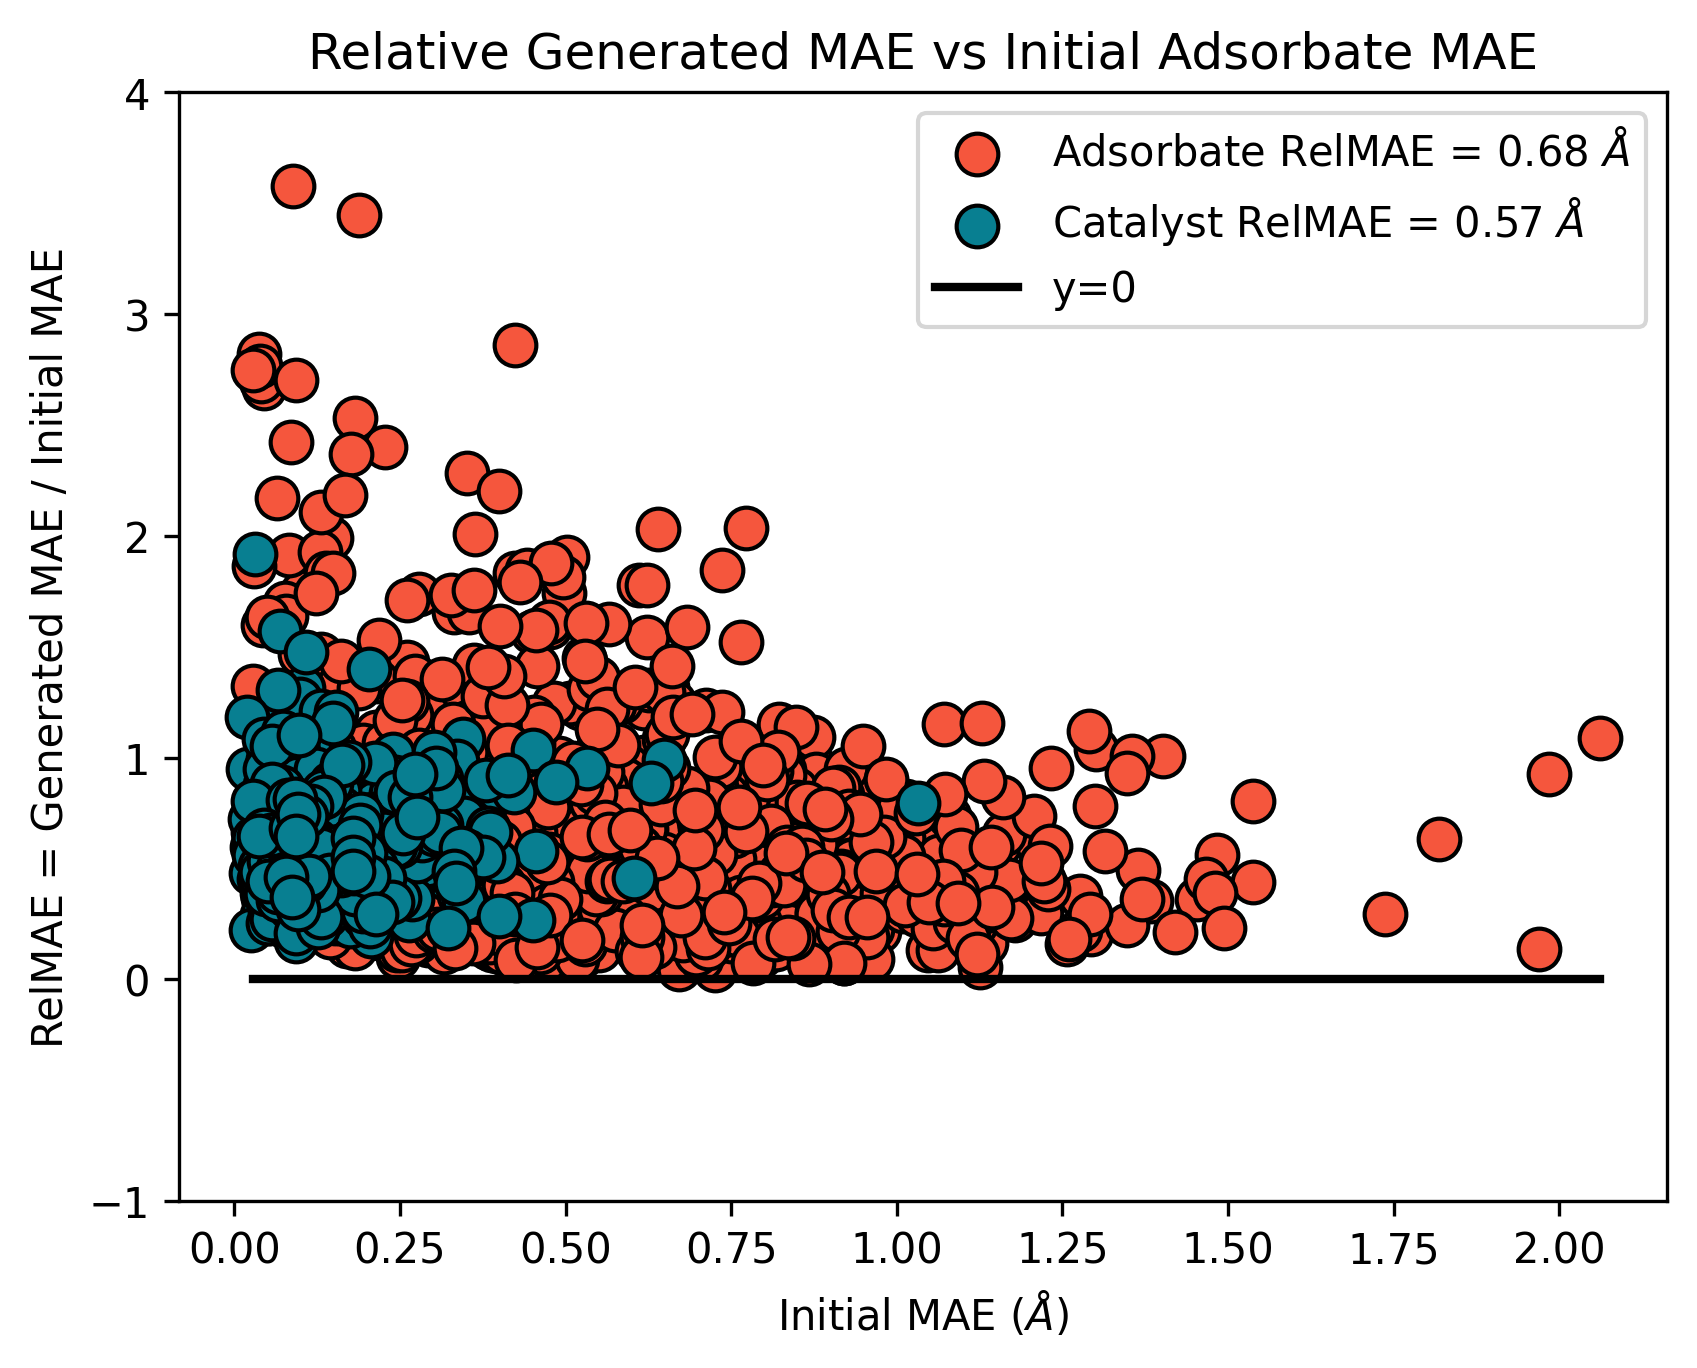

In [9]:
delta_cat = generated_cat_mae / initial_cat_mae
delta_ads = generated_ads_mae / initial_ads_mae

plt.figure(dpi=300)

plt.ylim(-1, 4)
plt.scatter(
    initial_ads_mae,
    delta_ads,
    s=100,      # or e.g. 5 + 3*counts to exaggerate
    edgecolors="black", 
    color="#F5563D",
    label=f'Adsorbate RelMAE = {delta_ads.mean():.2f} $\AA$',
)

plt.scatter(
    initial_cat_mae,
    delta_cat,
    s=100,      # or e.g. 5 + 3*counts to exaggerate
    edgecolors="black", 
    color="#087F91",
    label=f'Catalyst RelMAE = {delta_cat.mean():.2f} $\AA$',
)
plt.plot(x_reg, np.zeros_like(x_reg), color="black", label="y=0", linewidth=2)
plt.xlabel("Initial MAE ($\AA$)")
plt.ylabel("RelMAE = Generated MAE / Initial MAE")
plt.title("Relative Generated MAE vs Initial Adsorbate MAE")
plt.legend()

**Results:**
- Plot 1 shows moderate correlation: adsorbates requiring large displacements tend to have higher generated MAE.
- Plot 2 reveals that the model does learn to handle large-displacement adsorbates—these cases show the largest relative improvements (RelMAE < 1).
- Interestingly, structures with small initial MAE are more likely to be made slightly worse (RelMAE > 1), though this does not contradict the first observation: an adsorbate with large initial MAE can be significantly improved while still having elevated final MAE due to the magnitude of required displacement.

### Mean Error Analysis: Systematic Bias Detection

To assess systematic bias in model predictions, we compute the mean error (ME), which captures the signed average displacement error. Unlike MAE, ME reveals whether the model consistently over- or under-predicts atomic positions.

**Key Questions:**
- Does the model systematically under/overpredict positions?
- Is there a correlation between over/underprediction and the required displacement magnitude?

**Results:**
- The mean error is approximately zero for both overall structures and adsorbate atoms, indicating the model is unbiased.
- The regression analysis shows no statistically significant correlation (R² ≈ 0), confirming that the model's prediction errors are independent of displacement magnitude.
- However, the variance of adsorbate predictions is substantially higher than for catalyst atoms, indicating the model over/underpredicts individual samples in roughly equal but significant quantities.

Text(0.5, 1.0, 'Generated ME vs Initial MAE')

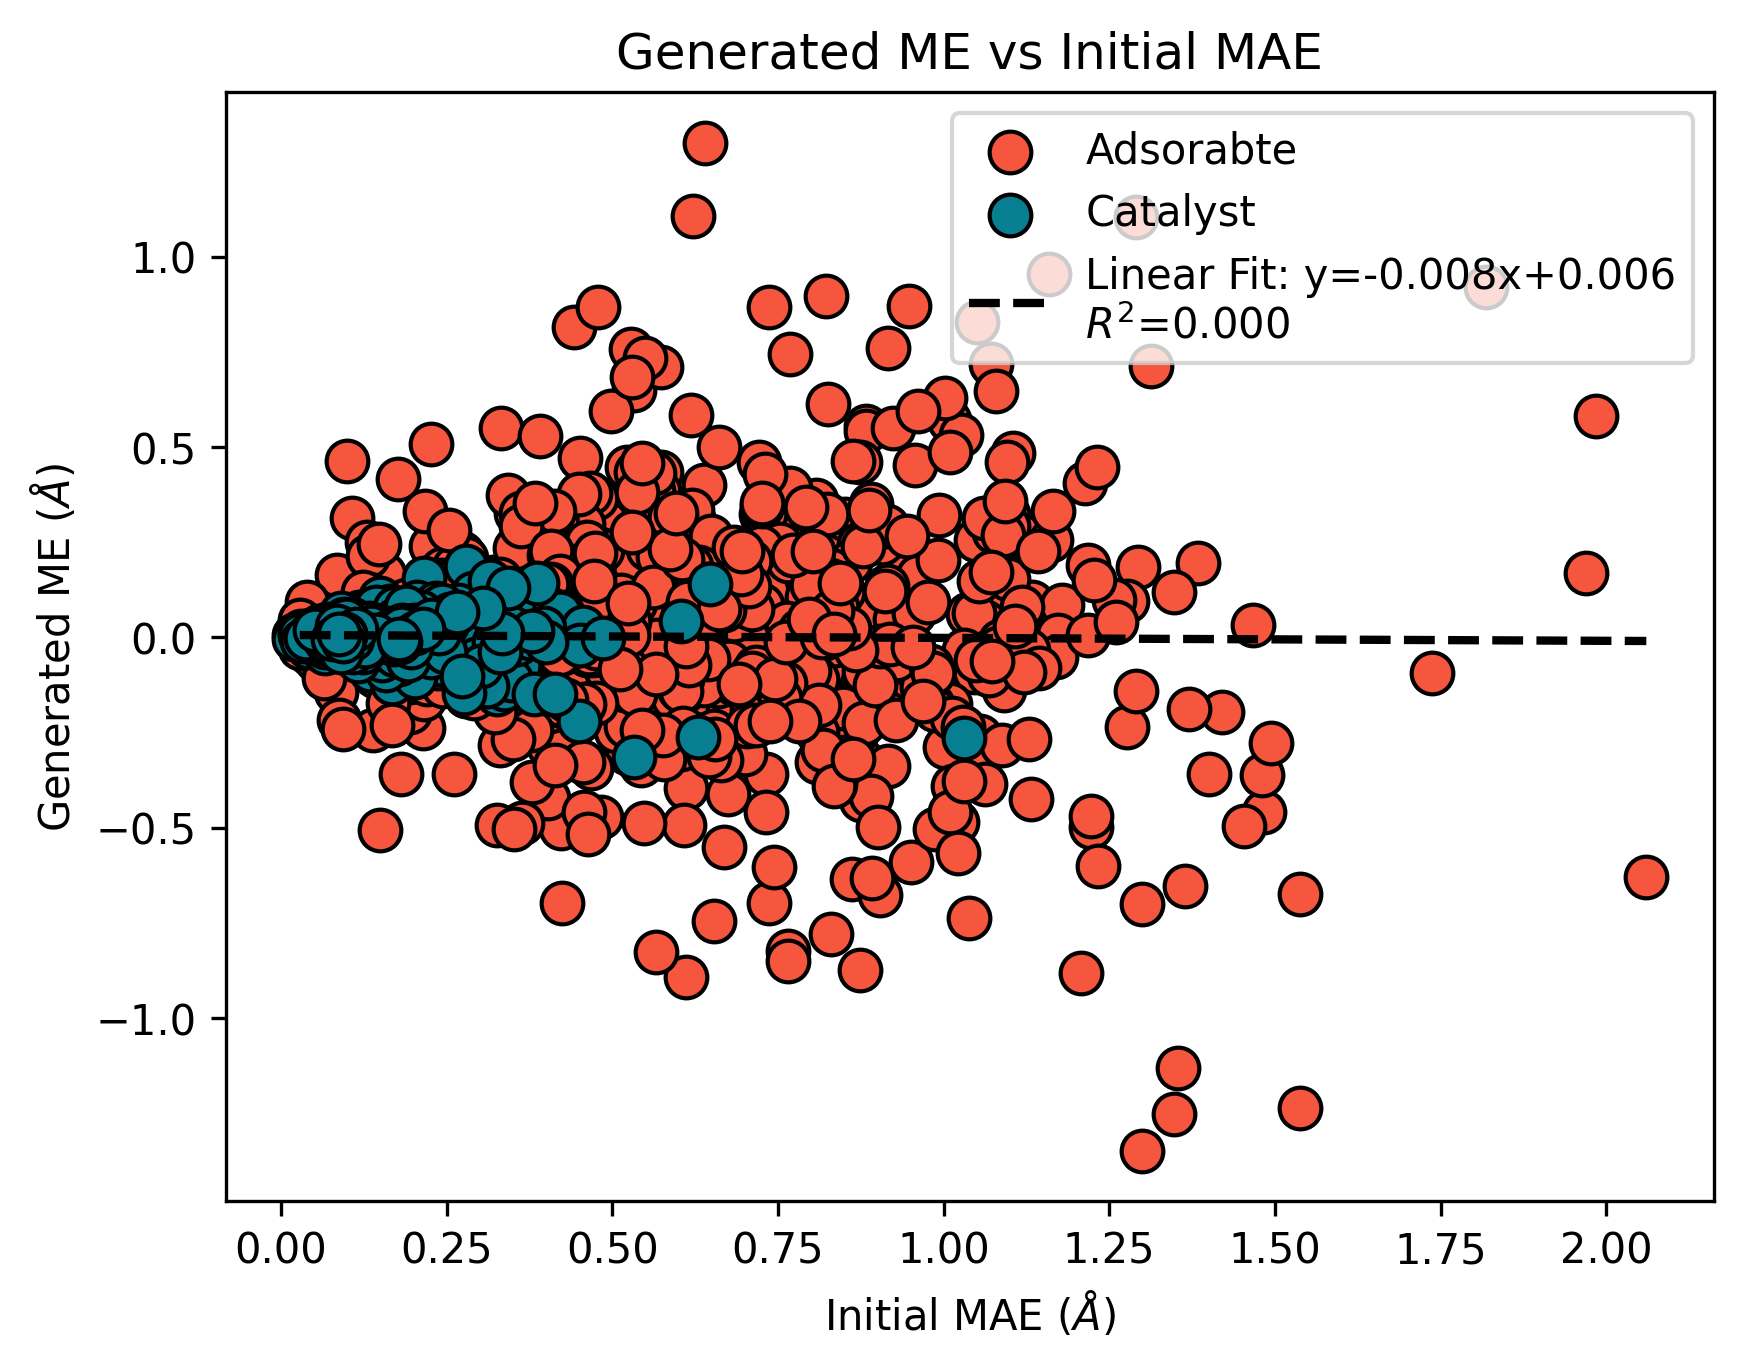

In [10]:
# Generate regression line
slope, intercept, r_value, p_value, std_err = stats.linregress(initial_mae, generated_me)
r_squared = r_value**2
x_reg = np.linspace(initial_ads_mae.min(), initial_ads_mae.max(), 100)
y_reg = slope * x_reg + intercept

plt.figure(dpi=300)
plt.scatter(
    initial_ads_mae,
    generated_ads_me,
    s=100,      # or e.g. 5 + 3*counts to exaggerate
    edgecolors="black", 
    color="#F5563D",
    label="Adsorabte"
)

plt.scatter(
    initial_cat_mae,
    generated_cat_me,
    s=100,      # or e.g. 5 + 3*counts to exaggerate
    edgecolors="black", 
    color="#087F91",
    label="Catalyst"
)
plt.plot(x_reg, y_reg, color="black", linewidth=2, linestyle="--", label=f"Linear Fit: y={slope:.3f}x+{intercept:.3f}\n$R^2$={r_squared:.3f}")
plt.ylabel("Generated ME ($\AA$)")
plt.xlabel("Initial MAE ($\AA$)")
plt.legend()
plt.title("Generated ME vs Initial MAE")


## Transition to Velocity Field Analysis

The structural MAE analysis provides limited insight into the specific failure modes of AdsFlow, particularly regarding adsorbate performance and bias since they are **per structure** metrics. To gain deeper understanding, we now examine the velocity field predictions directly—the actual regression target of the model.

## Velocity Field Predictions

The flow matching model regresses velocity field vectors that direct each atom from its initial position to its final relaxed position. Unlike the earlier per-structure statistics, velocity fields are defined per atom, enabling more granular analysis.

For our one-shot prediction approach, the velocity field represents the residual vector between relaxed coordinates (x₁, y₁, z₁) and initial coordinates (x₀, y₀, z₀).

In [11]:
u = np.load('val_ood_both_base-metrics/u.npy') 
u_hat = np.load('val_ood_both_base-metrics/u_hat.npy')
tags = np.load('val_ood_both_base-metrics/tags.npy')

u_ads = u[tags == 2]
u_cat = u[tags == 1]

u_hat_ads = u_hat[tags == 2]
u_hat_cat = u_hat[tags == 1]

### Distribution of True Velocity Field Norms

**Observation:** Adsorbate atoms have systematically larger velocity field vector norms (mean = ~1.24 Å) compared to catalyst atoms (mean = ~0.26 Å), with substantially higher variance. This confirms that adsorbates undergo larger displacements during relaxation, contributing to the difficulty in predicting their final positions.

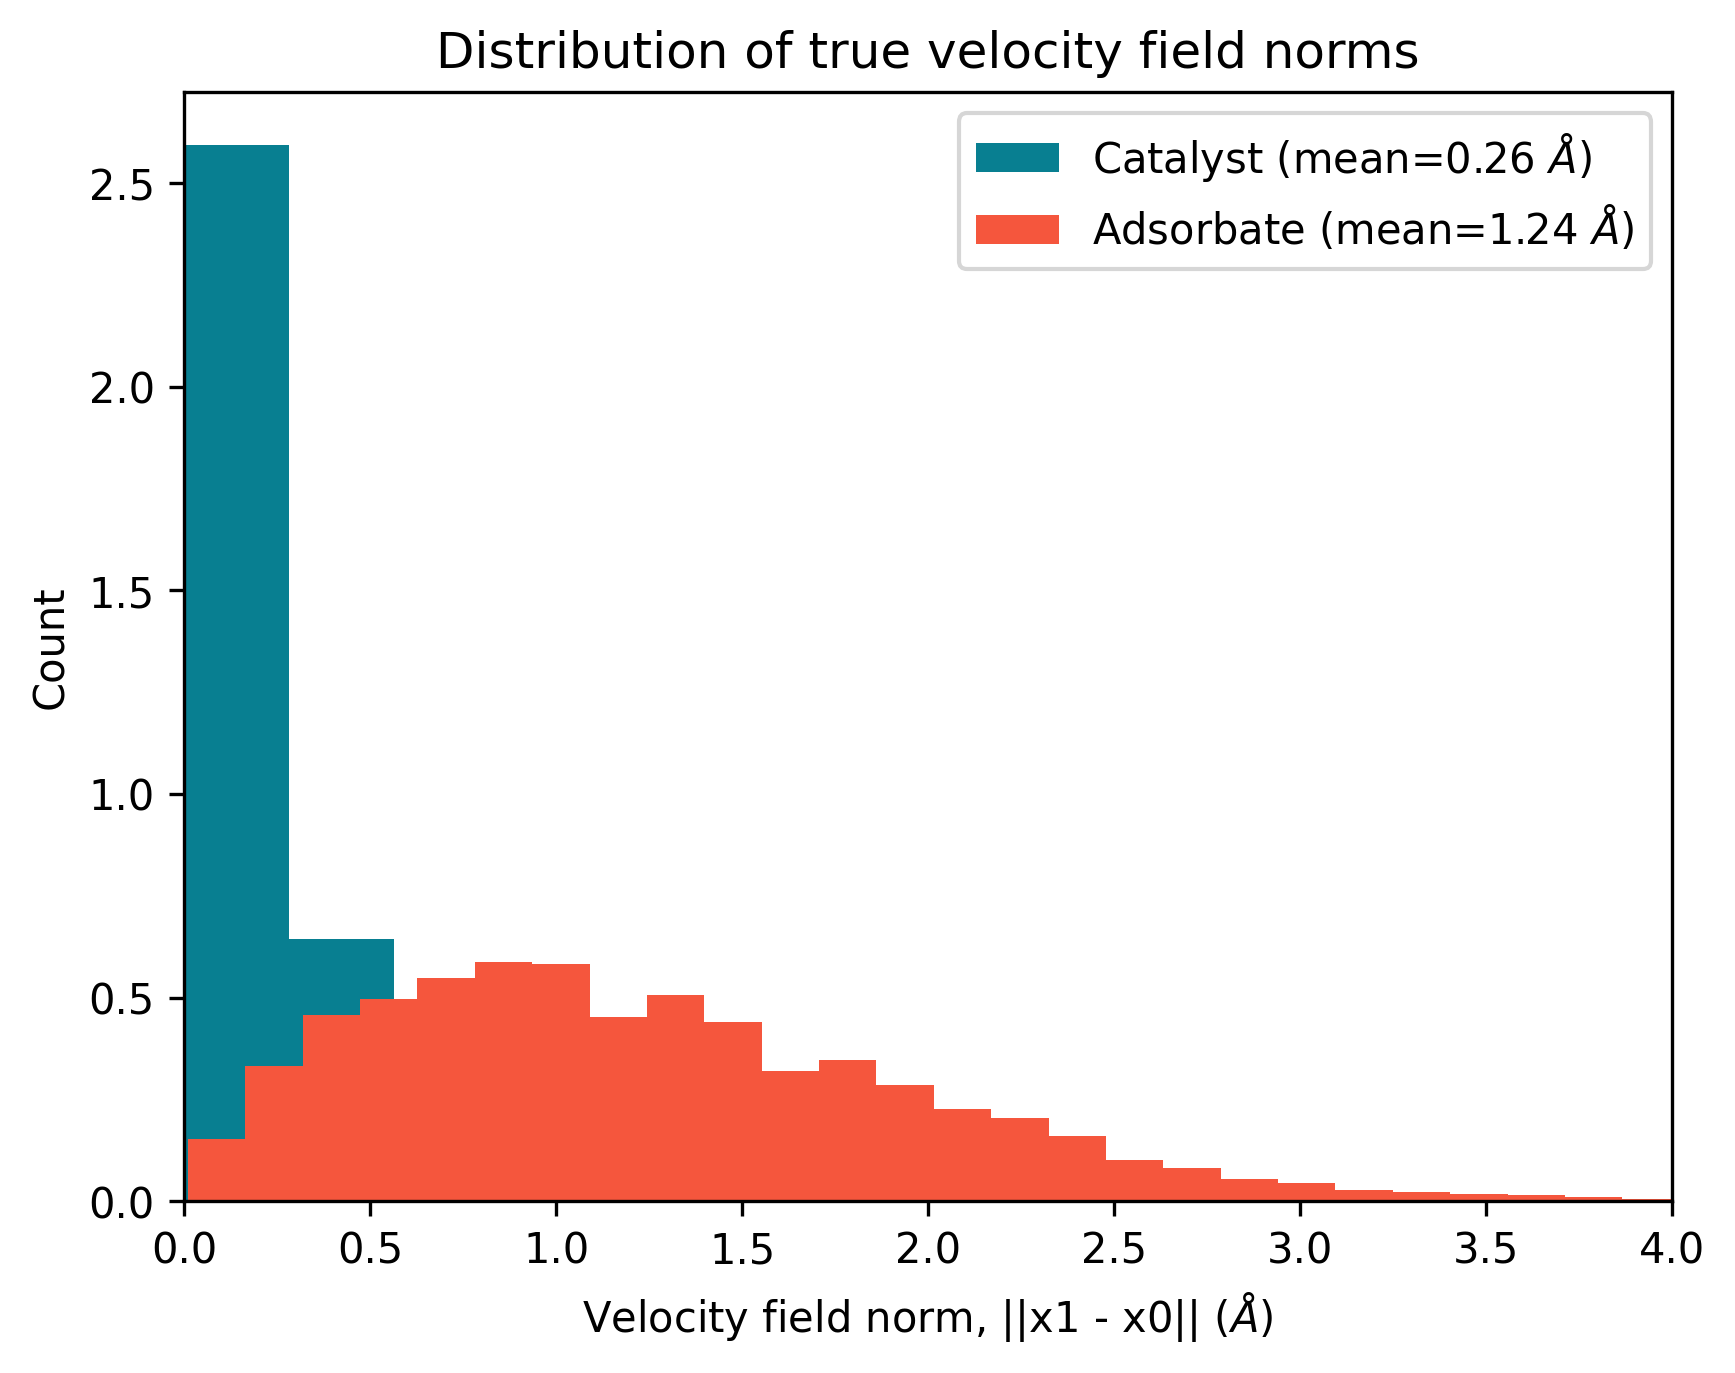

In [12]:
u_norm = np.linalg.norm(u, axis=1)
u_hat_norm = np.linalg.norm(u_hat, axis=1)

u_ads_norm = np.linalg.norm(u_ads, axis=1)
u_hat_ads_norm = np.linalg.norm(u_hat_ads, axis=1)

u_cat_norm = np.linalg.norm(u_cat, axis=1)
u_hat_cat_norm = np.linalg.norm(u_hat_cat, axis=1)

plt.figure(dpi=300)
plt.xlim(None, 4)
plt.hist(u_cat_norm, bins=30,  density=True, label=f'Catalyst (mean={u_cat_norm.mean():.2f} $\AA$)', color="#087F91")
plt.hist(u_ads_norm, bins=30,  density=True, label=f'Adsorbate (mean={u_ads_norm.mean():.2f} $\AA$)', color="#F5563D")
plt.xlabel("Velocity field norm, ||x1 - x0|| ($\AA$)")
plt.ylabel("Count")
plt.title("Distribution of true velocity field norms")
plt.legend()

### Predicted vs True Velocity Field Magnitudes

**Observations:**
- The model predicts velocity vectors with high variance around the true values for both atom types.
- Adsorbate atoms achieve an MAE of 0.40 Å, approximately 4× higher than catalyst atoms (MAE = 0.09 Å).
- **Critical finding:** The model systematically underestimates velocity field magnitudes for all atoms, but this effect is most pronounced for adsorbate atoms. Points consistently fall below the y=x line, indicating the model predicts smaller displacements than required.
- This underestimation was not apparent from structural MAE analysis alone, highlighting the value of per-atom velocity field diagnostics.

Text(0.5, 1.0, 'Regressed vs actual velocity field norms')

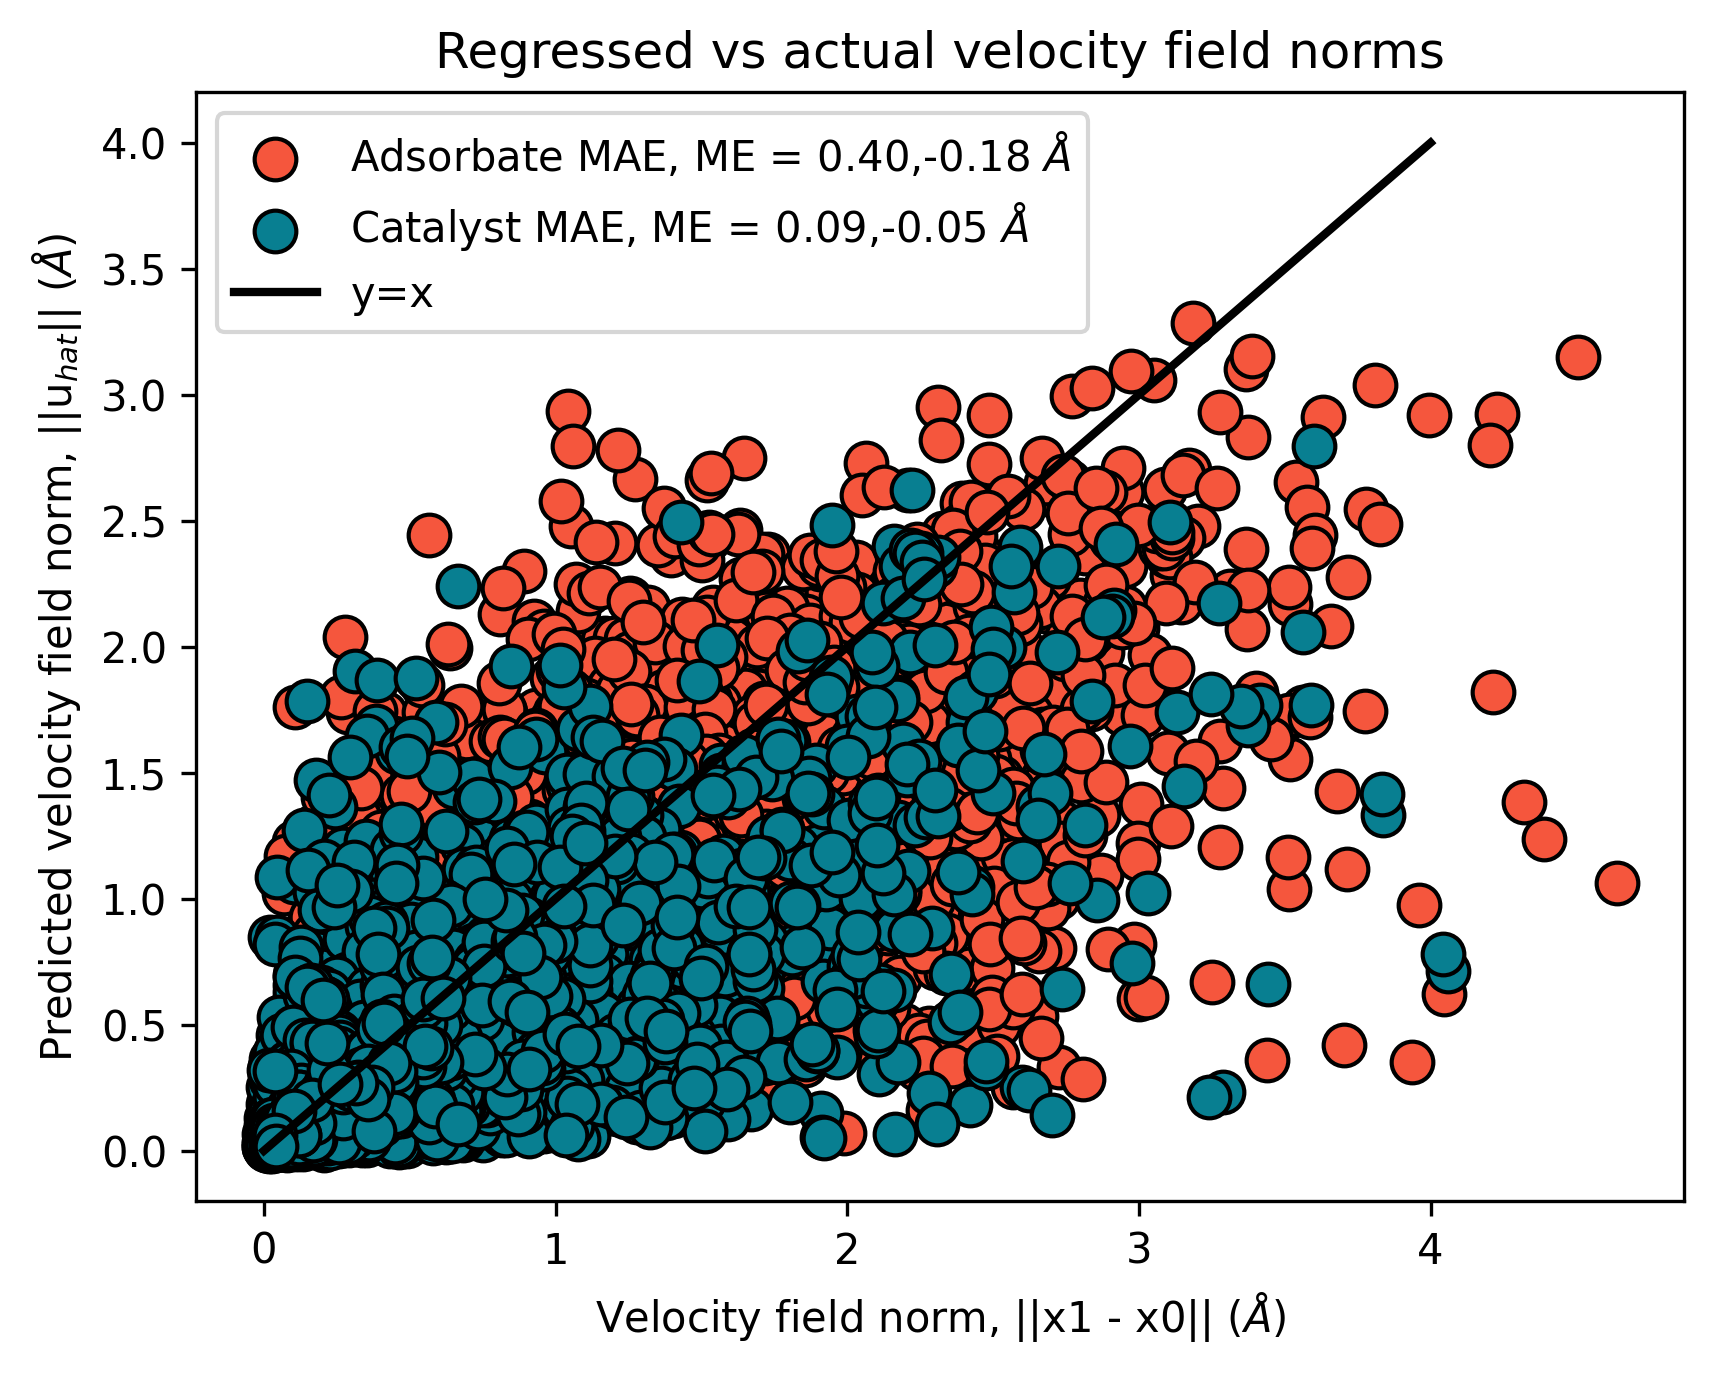

In [13]:
mask = u_cat_norm < 8
u_cat_norm = u_cat_norm[mask]
u_hat_cat_norm = u_hat_cat_norm[mask]

me_u_cat_norm = np.mean(u_hat_cat_norm - u_cat_norm)
me_u_ads_norm = np.mean(u_hat_ads_norm - u_ads_norm)

mae_u_cat_norm = np.abs(u_hat_cat_norm - u_cat_norm).mean()
mae_u_ads_norm = np.abs(u_hat_ads_norm - u_ads_norm).mean()

plt.figure(dpi=300)
plt.scatter(
    u_ads_norm,
    u_hat_ads_norm,
    s=100,      # or e.g. 5 + 3*counts to exaggerate
    edgecolors="black", 
    color="#F5563D",
    label=f'Adsorbate MAE, ME = {mae_u_ads_norm:.2f},{me_u_ads_norm:.2f} $\AA$',
)

plt.scatter(
    u_cat_norm,
    u_hat_cat_norm,
    s=100,      # or e.g. 5 + 3*counts to exaggerate
    edgecolors="black", 
    color="#087F91",
    label=f'Catalyst MAE, ME = {mae_u_cat_norm:.2f},{me_u_cat_norm:.2f} $\AA$',
)

# Generate regression line
x = np.arange(0, 5)
plt.plot(x, x, color="black", label="y=x", linewidth=2)

plt.legend()
plt.xlabel("Velocity field norm, ||x1 - x0|| ($\AA$)")
plt.ylabel("Predicted velocity field norm, ||u$_{hat}$|| ($\AA$)")
plt.title("Regressed vs actual velocity field norms")

### Directional Accuracy: Cosine Similarity Analysis

To verify the model correctly predicts the direction of atomic displacements (independent of magnitude), we compute the cosine similarity between predicted and true velocity vectors.

**Observation:** Both catalyst and adsorbate atoms show high mean cosine similarity scores (close to 1.0), confirming the model accurately predicts the direction of required displacements. Combined with the magnitude underestimation finding above, this suggests the primary model limitation is in predicting the correct displacement magnitude rather than direction.

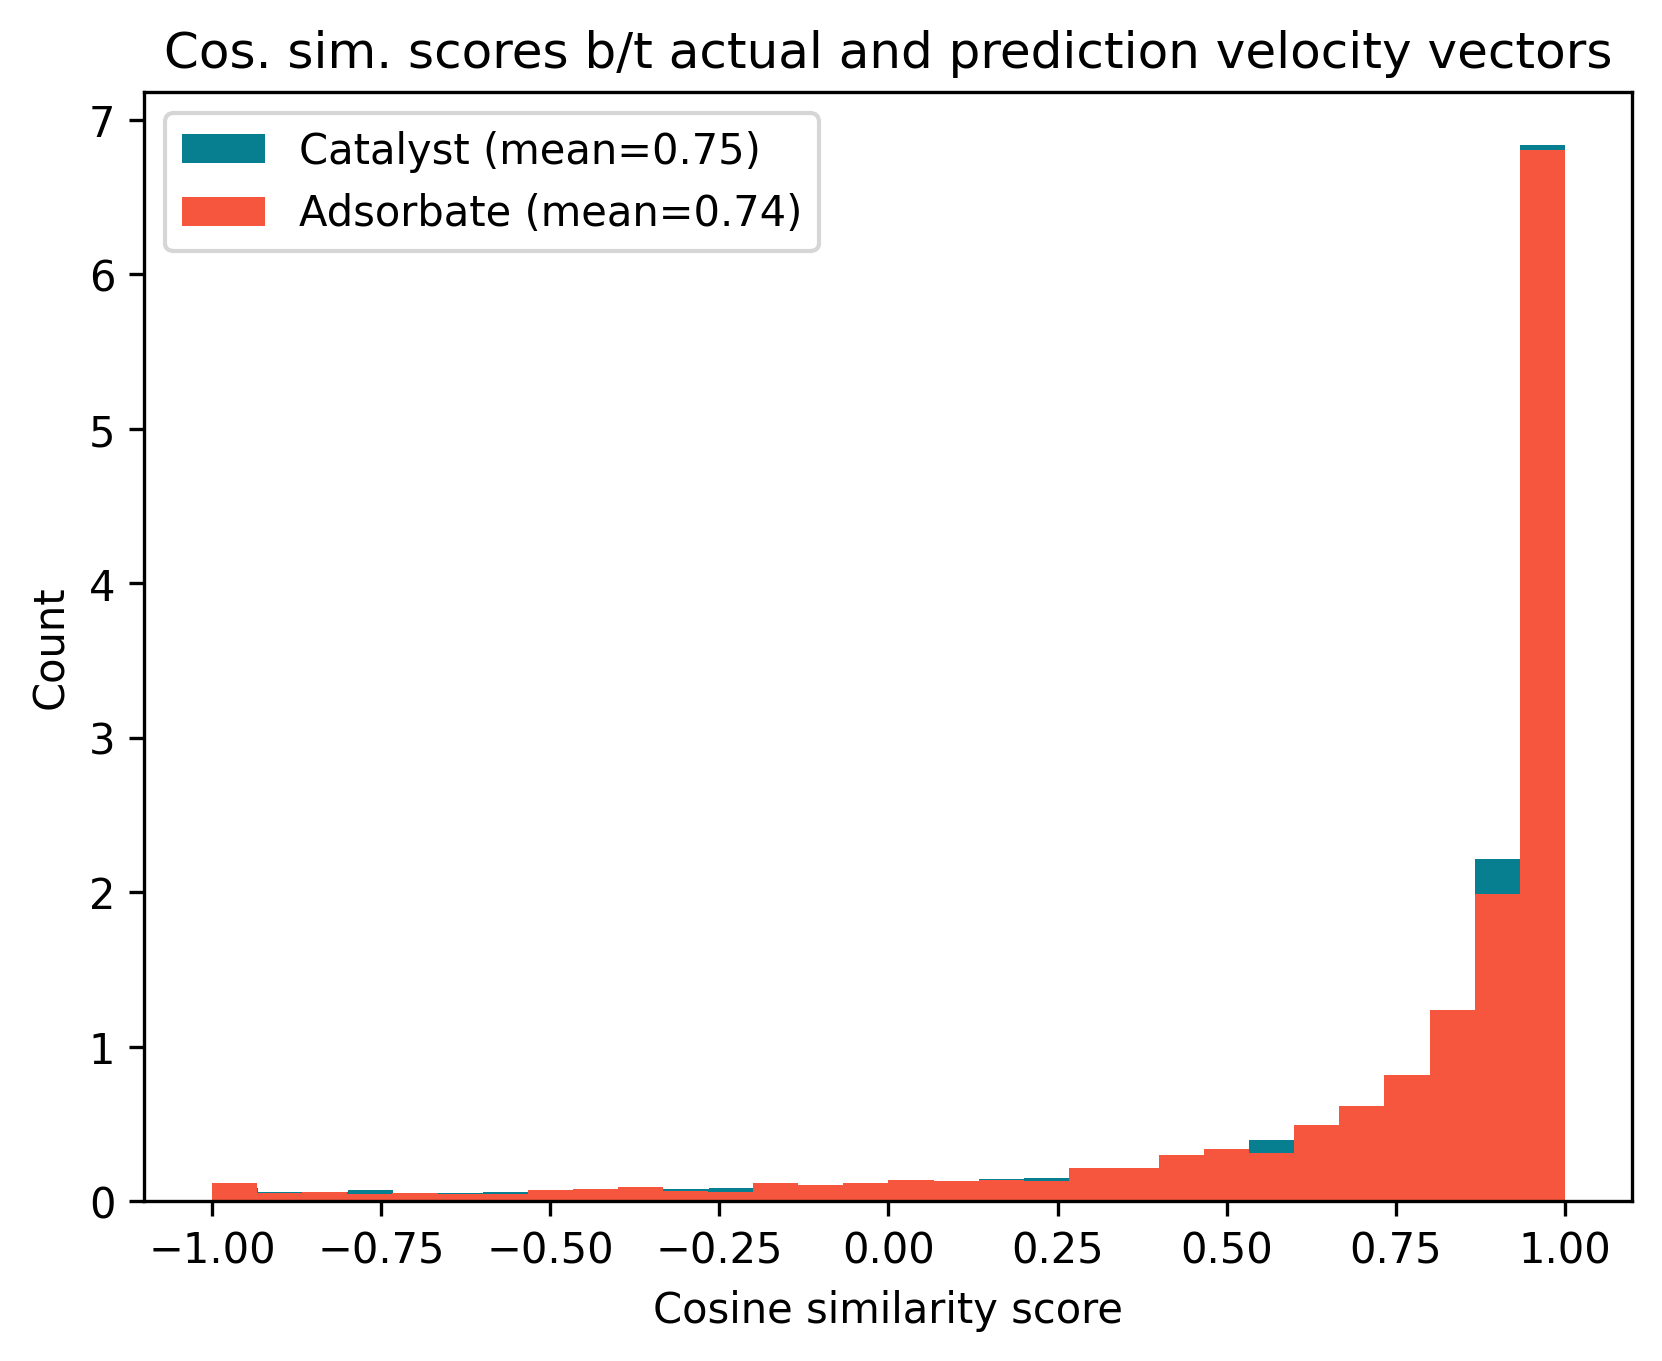

In [14]:

sim_matrix_cat = cosine_similarity(u_cat, u_hat_cat)
similarity_cat = np.diag(sim_matrix_cat)

sim_matrix_ads = cosine_similarity(u_ads, u_hat_ads)
similarity_ads = np.diag(sim_matrix_ads)

plt.figure(dpi=300)
plt.hist(similarity_cat, bins=30, density=True, label=f'Catalyst (mean={similarity_cat.mean():.2f})', color="#087F91")
plt.hist(similarity_ads, bins=30, density=True, label=f'Adsorbate (mean={similarity_ads.mean():.2f})', color="#F5563D")
plt.xlabel("Cosine similarity score")
plt.ylabel("Count")
plt.title("Cos. sim. scores b/t actual and prediction velocity vectors")
plt.legend()

# Conclusions

This diagnostic analysis reveals the following key insights about AdsFlow performance:

## Strengths
1. **Significant improvement over initial structures:** AdsFlow reduces MAE by 0.08 Å on average.
2. **Correct directional prediction:** High cosine similarity scores confirm the model accurately predicts the direction of atomic displacements.
3. **Robust architecture choice:** EquiformerV2 demonstrates superior generalization compared to GemNet-OC.

## Limitations and Opportunities
1. **Magnitude underestimation:** The model systematically underestimates velocity field magnitudes, particularly for adsorbate atoms. This represents the primary avenue for improvement.
2. **Adsorbate challenge:** Adsorbates inherently require larger displacements and exhibit higher prediction variance, consistent with their underrepresentation in the training distribution.

## Recommended Next Steps
Since we have already tried weighting adsorbate atoms more in the loss function, we should try to remove the distractive catalayst atoms all together, i.e., have the model target adsorabte atoms + catalayst atoms within some cutoff. 